In [99]:
import pandas as pd
#Charger la base de donnees
df = pd.read_csv("titanic.csv")
data= df.copy()
data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [100]:
#Explorer la base de donnees
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [101]:
#Calcul des valeurs manquantes danas chaque colonne
data.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [102]:
#Decrire la bdd pour decouvrir s'il y en a des anomalies 
data.describe()


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [103]:
#Renommer les colonnes
data = data.rename(columns={
    "Pclass" : "PassengerClass",
    "SibSp" : "Siblings/Spouses",
    "Parch" : "Parents/Children",
    "Fare": "Prix"
})

In [104]:
#Remplacer les valeurs manquantes de l'age par la mediane 
data["Age"] = data["Age"].fillna(data["Age"].median())

In [105]:
#Maintenant on laisse juste les colonnes utiles 
data = data[["Survived","PassengerClass","Sex", "Age","Siblings/Spouses", "Parents/Children","Prix","Embarked"]]

In [106]:
#transformer les catégories en nombres entiers que les modèles peuvent utiliser
from sklearn.preprocessing import LabelEncoder 
 
le = LabelEncoder() 
data['Sex'] = le.fit_transform(data['Sex']) 
data['Embarked'] = le.fit_transform(data['Embarked']) 

In [107]:
#Separer les donnees en 2 parties , training et test
X = data.drop('Survived', axis=1) 
y = data['Survived'] 
 
from sklearn.model_selection import train_test_split 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [108]:
#Importer les modeles logistic regression et random forest classifier
from sklearn.linear_model import LogisticRegression 
from sklearn.ensemble import RandomForestClassifier 

#Creer nos modeles log_model et rf_model
log_model = LogisticRegression(max_iter=1000) 
rf_model = RandomForestClassifier(n_estimators=100, random_state=42) 

#Entrainer nos modeles
log_model.fit(X_train, y_train) 
rf_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [109]:
#Evaluer nos modeles
from sklearn.metrics import accuracy_score, classification_report 

y_pred_log = log_model.predict(X_test) 
y_pred_rf = rf_model.predict(X_test) 

#Calcul de l'accuracy des 2 modeles 
print('Accuracy (Logistic):', accuracy_score(y_test, y_pred_log)) 
print('Accuracy (Random Forest):', accuracy_score(y_test, y_pred_rf)) 

#Ce classification_report repond a 4 questions:
#Precision: parmi les passagers prédits comme survivants, quelle proportion a réellement survécu ?
#Recall: parmi tous les vrais survivants, combien ont été reconnus par le modèle ?
#F1-score: combine la précision et le rappel. Elle est utile pour avoir une vue d'ensemble de ces deux critères.
#support: C'est le nombre d'exemples réels de chaque classe dans les données de test.
print(classification_report(y_test, y_pred_rf))

Accuracy (Logistic): 0.8100558659217877
Accuracy (Random Forest): 0.8212290502793296
              precision    recall  f1-score   support

           0       0.83      0.88      0.85       105
           1       0.81      0.74      0.77        74

    accuracy                           0.82       179
   macro avg       0.82      0.81      0.81       179
weighted avg       0.82      0.82      0.82       179



In [112]:
#installer seaborn
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [116]:
### Interprétation de la matrice de confusion

#La matrice de confusion permet d'évaluer les performances du modèle Random Forest pour prédire la survie des passagers du Titanic.
#Le modèle a correctement identifié 92 passagers qui n'ont pas survécu et 55 passagers qui ont survécu. Cependant, il a commis 13 erreurs en prédisant la survie de passagers qui n'ont pas survécu, ainsi que 19 erreurs en prédisant que certains survivants n'avaient pas survécu.
#L'accuracy du modèle est d'environ 82,1 %, ce qui signifie que 147 prédictions sur 179 sont correctes. Le rappel pour la classe des survivants est d'environ 74,3 % : le modèle identifie correctement environ 74,3 % des passagers qui ont réellement survécu.
#En conclusion, le modèle obtient des résultats encourageants, mais il ne prédit pas correctement tous les passagers. Il serait intéressant d'examiner les erreurs et de comparer ses performances avec celles de la régression logistique afin de déterminer quel modèle est le plus adapté à cet exercice.

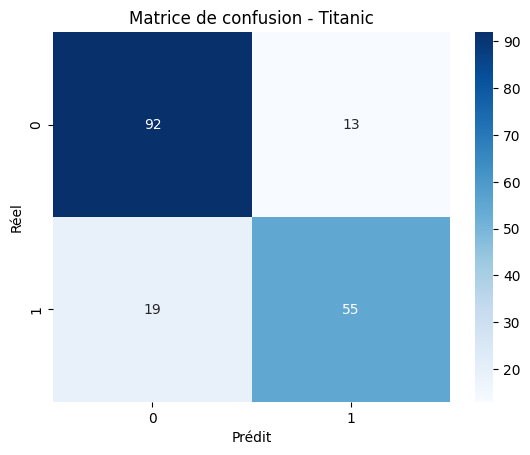

In [113]:
from sklearn.metrics import confusion_matrix  
import matplotlib.pyplot as plt 
import seaborn as sns
cm = confusion_matrix(y_test, y_pred_rf) 
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues') 
plt.title('Matrice de confusion - Titanic') 
plt.xlabel('Prédit') 
plt.ylabel('Réel') 
plt.show() 